# 02 - Checking the Extracted Features

**Goal:** Find out which of the extracted features show a difference between real and fake clips, and whether any look too good to be true.

*Note:* We use the 2019 LA **train** and **dev** features at 4 s, with silence trimmed. The 2019 **eval** and all of the 2021 data stay untouched until the final test.

## Contents

1. Setup
2. Turning Each Feature into Numbers per Clip
3. Loading the Features
4. Exploring the Features
5. How Well Does Each Number Separate Real from Fake?
6. Do the Scores Hold on Dev?
7. Features to Watch
8. Summary

## Setup

Loads the libraries and the project's shared code, and defines the names used throughout.

- **`autoreload`**: if you edit a file in `src/`, the notebook picks up the change without restarting.
- **`src/data.py`**: `load_features` joins the saved batches of one feature and returns the features with their labels.
- **`src/features.py`**: `FEATURES` lists the eight feature groups.
- **`REAL` / `FAKE`**: the label numbers (0 = real, 1 = fake), as in the first notebook.

In [29]:
# Re-import edited files from src/ automatically, and show plots inside the notebook
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Let the notebook import our shared code from src/
import sys
sys.path.insert(0, "../src")

# Tables, numbers and plots
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Score for how well one number separates real from fake
from sklearn.metrics import roc_auc_score

# Project code: audio settings, the feature list, and the feature loader
from config import CLIP_SECONDS, N_LFCC, N_MELS, N_MFCC
from data import load_features
from features import FEATURES

# Label numbers, plus a readable name and plot color for each
REAL, FAKE = 0, 1
NAMES = {REAL: "real", FAKE: "fake"}
COLORS = {REAL: "tab:blue", FAKE: "tab:red"}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Turning Each Feature into Numbers per Clip

Most features are a grid: one row per coefficient or frequency band, one column per moment in time. To compare real and fake we boil each row down to two numbers per clip: its **average** over time and its **spread** (standard deviation) over time. The spread is how much the feature changes during the clip.

Jitter, shimmer and the noise features are already one number per clip, so they are used as they are. For pitch we also add the **voiced fraction**: the share of frames where a pitch was found.

In [30]:
# One name per row of each feature, in the order the rows are saved
ROW_NAMES = {
    "mfcc": [f"{p}mfcc{i}" for p in ("", "d_", "dd_") for i in range(N_MFCC)],
    "lfcc": [f"lfcc{i}" for i in range(N_LFCC)],
    "logmel": [f"logmel{i}" for i in range(N_MELS)],
    "cqt": [f"cqt{i}" for i in range(84)],
    "spectral": ["centroid", "flatness", "rolloff", "flux"],
    "pitch": ["f0", "voiced_prob"],
    "jitter_shimmer": ["jitter", "shimmer"],
    "noise": ["noise_mean_db", "noise_std_db"],
}


def summarize(feature, x):
    """One table row per clip. Columns are named "<feature>:<row>:<mean or std>"."""
    names = ROW_NAMES[feature]
    if x.ndim == 2:  # already one number per clip
        return pd.DataFrame(x, columns=[f"{feature}:{n}" for n in names])

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # pitch is NaN where there is no pitch
        mean, std = np.nanmean(x, axis=2), np.nanstd(x, axis=2)

    cols = {}
    for i, n in enumerate(names):
        cols[f"{feature}:{n}:mean"] = mean[:, i]
        cols[f"{feature}:{n}:std"] = std[:, i]
    if feature == "pitch":
        cols["pitch:voiced_fraction"] = (~np.isnan(x[:, 0, :])).mean(axis=1)
    return pd.DataFrame(cols)

## Loading the Features

Each feature is loaded, boiled down with the function above, and the full grid is thrown away to save memory.

In [31]:
summary, labels = {}, {}
for split in ("train", "dev"):
    parts = []
    for feature in FEATURES:
        x, labels[split] = load_features(feature, split, CLIP_SECONDS)
        parts.append(summarize(feature, x))
    summary[split] = pd.concat(parts, axis=1).astype(np.float32)
    print(f"{split}: {summary[split].shape[0]:,} clips, {summary[split].shape[1]} numbers per clip")

train: 25,380 clips, 505 numbers per clip
dev: 24,844 clips, 505 numbers per clip


In [32]:
# How many numbers each feature turned into, and how many are missing
group = pd.Series([c.split(":")[0] for c in summary["train"].columns], index=summary["train"].columns)
pd.DataFrame({
    "numbers per clip": group.value_counts(),
    "missing (train)": summary["train"].isna().mean().groupby(group).mean().round(3),
}).loc[list(FEATURES)]

,numbers per clip,missing (train)
mfcc,120,0.000
lfcc,40,0.000
logmel,160,0.000
cqt,168,0.000
spectral,8,0.000
pitch,5,0.001
jitter_shimmer,2,0.000
noise,2,0.000


## Exploring the Features

What each of the eight features actually looks like in the data. For each one there are two views:

- **Examples:** the feature for 3 real and 3 fake train clips, picked at random (fixed seed, so the same clips every time). Real clips are in the top row, fake in the bottom row.
- **Across the data:** the same feature summarized over all train clips, real and fake separately.

This is only looking and noting what stands out. Nothing is scored here.

In [33]:
from IPython.display import display

from config import HOP_LENGTH, SAMPLE_RATE

# Pick 3 real and 3 fake train clips at random (fixed seed so the examples repeat). The index
# of each one is its row in the saved features.
train_table = labels["train"]
n_each = 3
sample_idx = np.concatenate([
    train_table[train_table.label == l].sample(n_each, random_state=0).index.to_numpy() for l in (REAL, FAKE)
])
sample_label = train_table.loc[sample_idx, "label"].to_numpy()
sample_file = train_table.loc[sample_idx, "file"].to_numpy()

# Reload each saved feature once. Keep the full grid for the example clips, and for ALL train
# clips keep each row's average over time, to see what is typical across the data.
examples, row_means = {}, {}
for feature in FEATURES:
    x, _ = load_features(feature, "train", CLIP_SECONDS)
    examples[feature] = x[sample_idx]
    if x.ndim == 2:  # already one number per clip
        row_means[feature] = x
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # pitch is NaN where there is no pitch
            row_means[feature] = np.nanmean(x, axis=2)
    del x

# Time of each frame in seconds
t = np.arange(examples["mfcc"].shape[2]) * HOP_LENGTH / SAMPLE_RATE
{f: v.shape for f, v in examples.items()}

{'mfcc': (6, 60, 126),
 'lfcc': (6, 20, 126),
 'logmel': (6, 80, 126),
 'cqt': (6, 84, 126),
 'spectral': (6, 4, 126),
 'pitch': (6, 2, 126),
 'jitter_shimmer': (6, 2),
 'noise': (6, 2)}

In [34]:
# What each row's per-clip value is, with units, for the x-axis of the histograms
HIST_LABELS = {
    "centroid": "centroid, clip average (Hz)",
    "flatness": "flatness, clip average",
    "rolloff": "rolloff, clip average (Hz)",
    "flux": "flux, clip average",
    "f0": "pitch, clip average (Hz)",
    "voiced_prob": "voiced probability, clip average",
    "jitter": "jitter",
    "shimmer": "shimmer",
    "noise_mean_db": "noise level (dB)",
    "noise_std_db": "noise spread (dB)",
}


def clip_title(i):
    return f"{NAMES[sample_label[i]]}: {sample_file[i]}"


def show_grids(feature, rows=None, ylabel="row"):
    """One heatmap per example clip (real on the top row, fake on the bottom) on a shared color scale."""
    grids = examples[feature] if rows is None else examples[feature][:, rows]
    lo, hi = np.nanpercentile(grids, [1, 99])
    fig, axes = plt.subplots(2, n_each, figsize=(4 * n_each, 5), sharex=True, sharey=True)
    for i, ax in enumerate(axes.ravel()):
        im = ax.imshow(
            grids[i], origin="lower", aspect="auto", cmap="magma", vmin=lo, vmax=hi,
            extent=[0, CLIP_SECONDS, 0, grids.shape[1]],
        )
        ax.set_title(clip_title(i), fontsize=9)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes[-1]:
        ax.set_xlabel("time (s)")
    fig.colorbar(im, ax=axes, label=feature)


def show_profile(feature, rows=None, xlabel="row", ylabel=""):
    """Each row's average over time, then the spread of that across ALL train clips.

    Line = median clip, shading = the middle 80% of clips.
    """
    m = row_means[feature] if rows is None else row_means[feature][:, rows]
    is_fake = (train_table["label"] == FAKE).to_numpy()
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for label, mask in ((REAL, ~is_fake), (FAKE, is_fake)):
        p10, p50, p90 = np.nanpercentile(m[mask], [10, 50, 90], axis=0)
        ax.plot(p50, color=COLORS[label], label=NAMES[label])
        ax.fill_between(range(len(p50)), p10, p90, color=COLORS[label], alpha=0.2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{feature}: average over time, all {len(m):,} train clips")
    ax.legend()
    plt.tight_layout()


def show_distributions(feature):
    """One histogram per row of a feature: each clip's average over time, all train clips."""
    m = row_means[feature]
    is_fake = (train_table["label"] == FAKE).to_numpy()
    fig, axes = plt.subplots(1, m.shape[1], figsize=(4 * m.shape[1], 3.3))
    axes = np.atleast_1d(axes)
    for r, ax in enumerate(axes):
        ok = np.isfinite(m[:, r])
        lo, hi = np.percentile(m[ok, r], [1, 99])
        for label, mask in ((REAL, ~is_fake), (FAKE, is_fake)):
            ax.hist(m[mask & ok, r], bins=40, range=(lo, hi), density=True, alpha=0.6,
                    color=COLORS[label], label=NAMES[label])
        ax.set_xlabel(HIST_LABELS[ROW_NAMES[feature][r]])
    axes[0].set_ylabel("share of clips (density)")
    axes[0].legend()
    plt.tight_layout()

### MFCC

A compact description of the shape of the spectrum in each frame: 20 coefficients, plus how fast each one is changing (first change) and how fast that change is changing (second change). 60 rows per frame in total. The first plot is the 20 coefficients. The second plot is the two change blocks stacked, with rows 0 to 19 the first change and rows 20 to 39 the second change.

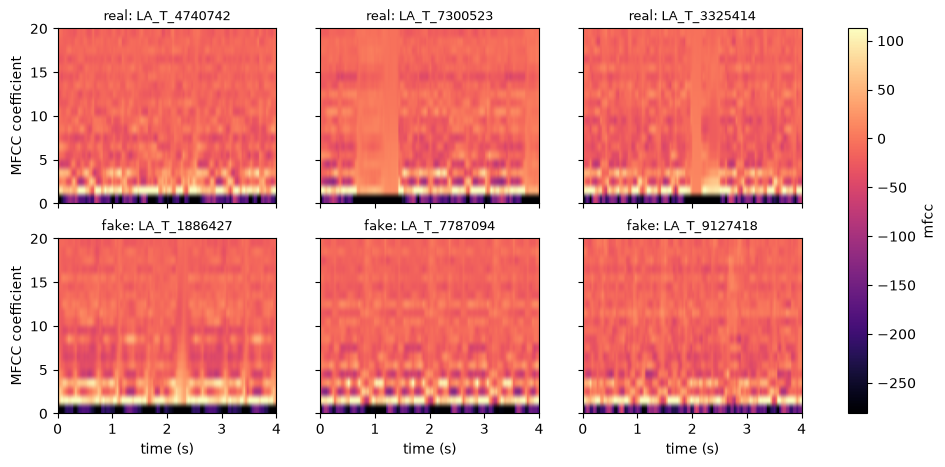

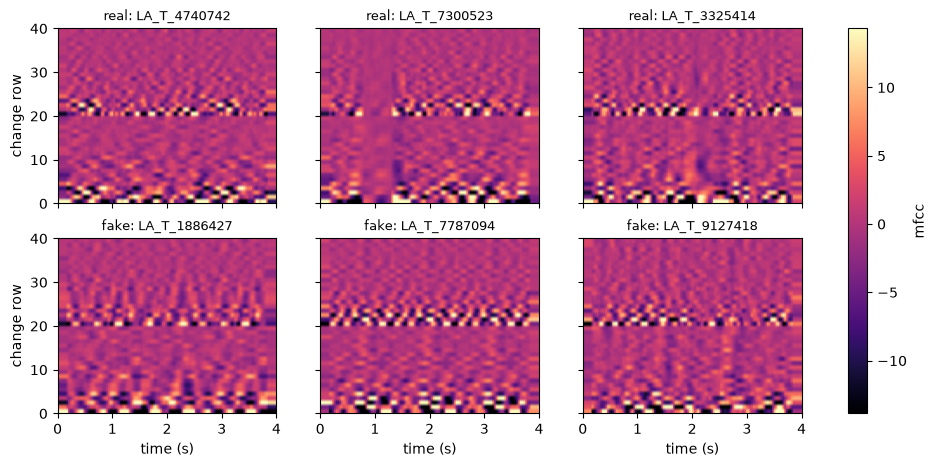

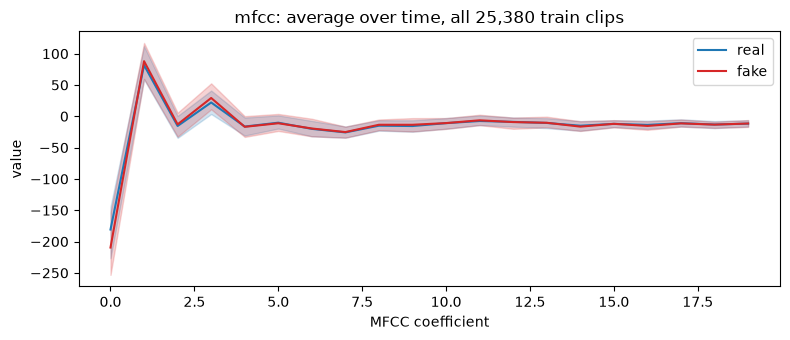

In [35]:
static = slice(0, N_MFCC)
change = slice(N_MFCC, 3 * N_MFCC)

show_grids("mfcc", rows=static, ylabel="MFCC coefficient")
show_grids("mfcc", rows=change, ylabel="change row")
show_profile("mfcc", rows=static, xlabel="MFCC coefficient", ylabel="value")

**What stands out**

- Only the first two coefficients are large. Coefficient 0 sits far below zero (roughly -200, a measure of overall loudness) and coefficient 1 far above (roughly +90). The rest stay near zero.
- In the examples, the dark band in coefficient 0 gets wider in the pauses and the other coefficients flatten out, so you can see where the speech stops. The second real clip has a long pause around 1 s.
- The two change blocks are small (about plus or minus 10) and speckled, with most of the activity in the lowest few coefficients of each block. They show where the sound changes quickly.
- Across all train clips the real and fake lines almost overlap. The one visible gap is coefficient 0, where the fake median is a little lower than the real one. The shaded bands overlap almost completely.

### LFCC

Like MFCC, but with evenly spaced frequency bands instead of the hearing-based spacing, so the high frequencies keep more detail. 20 coefficients per frame.

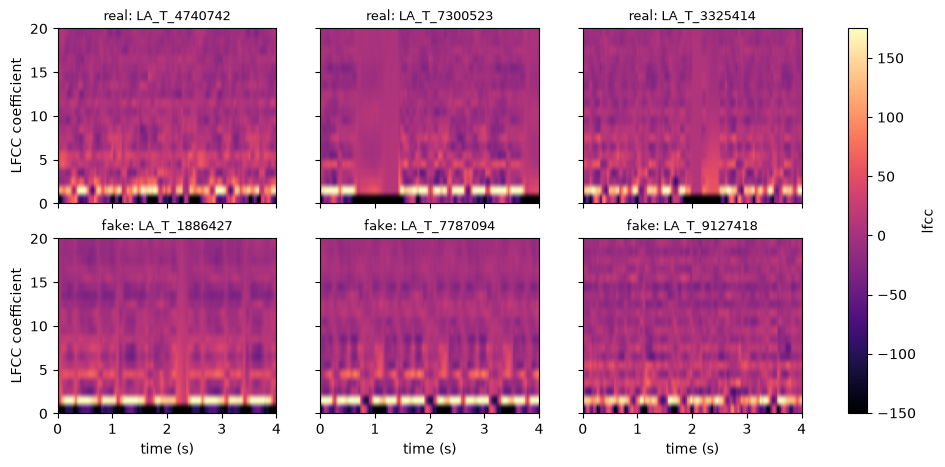

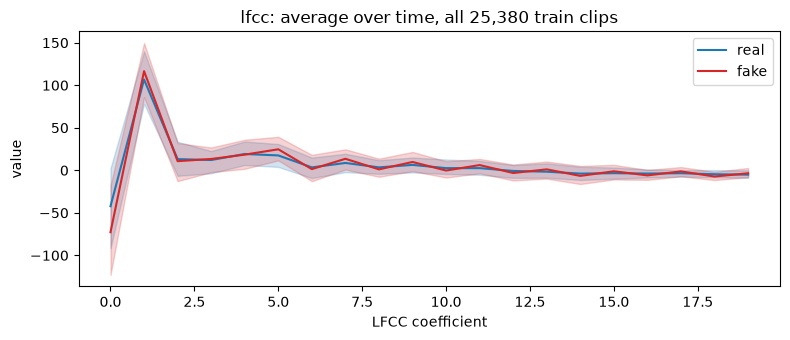

In [36]:
show_grids("lfcc", ylabel="LFCC coefficient")
show_profile("lfcc", xlabel="LFCC coefficient", ylabel="value")

**What stands out**

- It has the same layout as MFCC: coefficient 0 is strongly negative (roughly -40 to -70 on average) and coefficient 1 strongly positive (roughly +100), with the rest within about plus or minus 30 and settling near zero past coefficient 8 or so.
- The pauses show up the same way as in MFCC. In the second and third real clips, the long pauses turn most rows into a flat purple block.
- The values have a wider range than MFCC (the color scale runs from about -150 to +175).
- Across all train clips the lines are close. As with MFCC, the fake median is lower at coefficient 0 (roughly -70 against -40), and the shaded bands overlap heavily everywhere else.

### Log-mel spectrogram

The energy in 80 frequency bands spaced the way hearing works (finer at low frequencies), in dB, for each frame. This is the most direct picture of the sound.

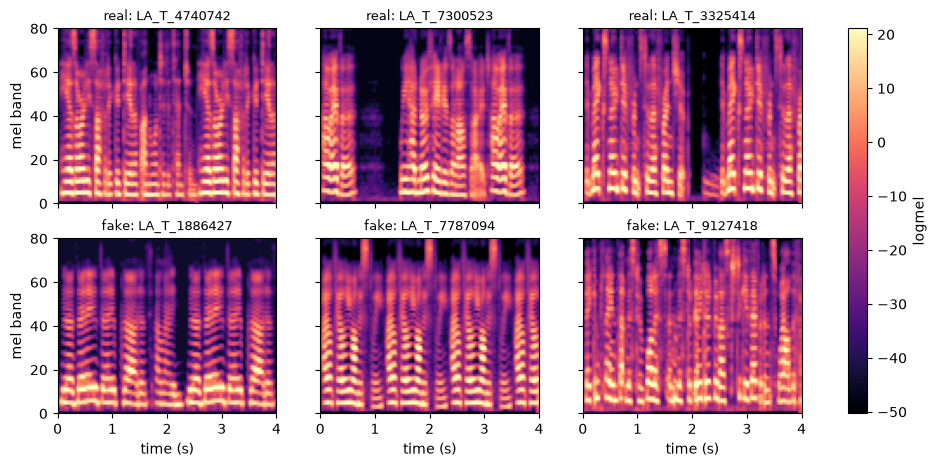

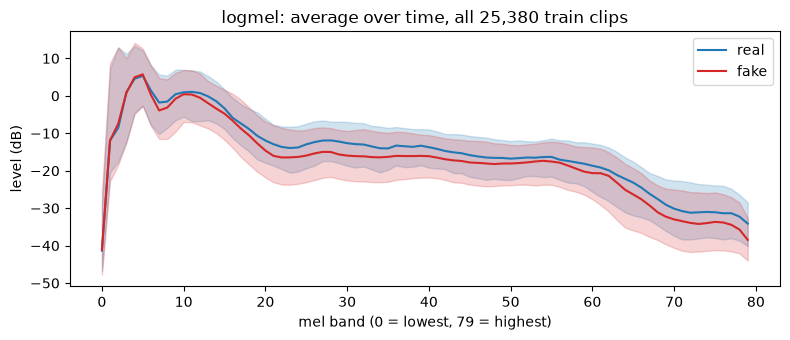

In [37]:
show_grids("logmel", ylabel="mel band")
show_profile("logmel", xlabel="mel band (0 = lowest, 79 = highest)", ylabel="level (dB)")

**What stands out**

- This is the most readable of the features. Speech shows up as bright vertical bursts, with stacked horizontal stripes in the lowest 30 or so bands (the voice's harmonics). The gaps between words are dark columns.
- The pauses differ a lot between clips. Two of the three real examples have long, deep pauses (around 0.5 to 1.3 s, or 2.1 to 2.4 s) where every band drops to about -50 dB. The fake examples have shorter or shallower gaps. With three clips each, that is something to look at, not a finding.
- Two of the three fake examples have bright energy in the top bands (60 to 80) during speech. The real examples are dimmer up there.
- Across all train clips both lines follow the same shape. Band 0 is nearly empty (about -40 dB), there is a sharp rise to a peak of about +5 dB at bands 4 to 5, a fall to about -13 dB by band 20, a plateau to about band 55, and then a drop to about -32 dB by band 75.
- The fake median sits a few dB below the real one from band 20 upward, but the 80% bands are wide (roughly plus or minus 10 dB) and overlap heavily.

### CQT

A constant-Q spectrogram with 84 bins spaced like musical notes, which makes the harmonics of a voice show up as evenly stacked lines. Values are in dB.

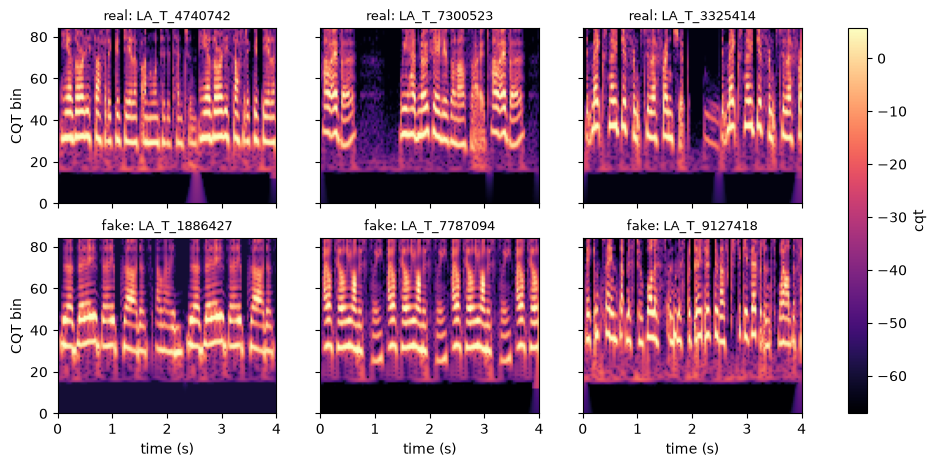

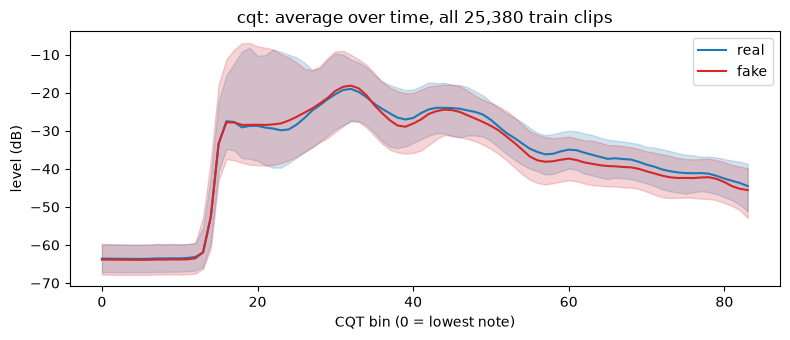

In [38]:
show_grids("cqt", ylabel="CQT bin")
show_profile("cqt", xlabel="CQT bin (0 = lowest note)", ylabel="level (dB)")

**What stands out**

- The harmonics show as clean, evenly stacked stripes, and they are curved where the pitch glides up or down. This shows the voice's structure more clearly than the log-mel.
- The lowest 15 or so bins are empty in every clip: a flat band at about -63 dB, and on the profile a flat line out to bin 13 before a steep jump. They cover frequencies below the range of the voice, so the bottom of this feature carries almost no information.
- In two of the three real examples (the first and third) there is a brief bump inside that empty band at about 2.5 s, which looks like a low-frequency thump. None of the fake examples has a clear one. With three clips each this may be chance.
- Across all train clips the real and fake lines almost overlap, with heavily overlapping bands. The profile has a bump around bin 30 and then falls toward -45 dB.

### Spectral shape

Four single-line features per frame: the **centroid** (where the "center of mass" of the spectrum is, in Hz), the **flatness** (near 1 for noise-like sound, near 0 for tonal sound), the **rolloff** (the frequency below which 85% of the energy sits) and the **flux** (how much the spectrum changed since the previous frame).

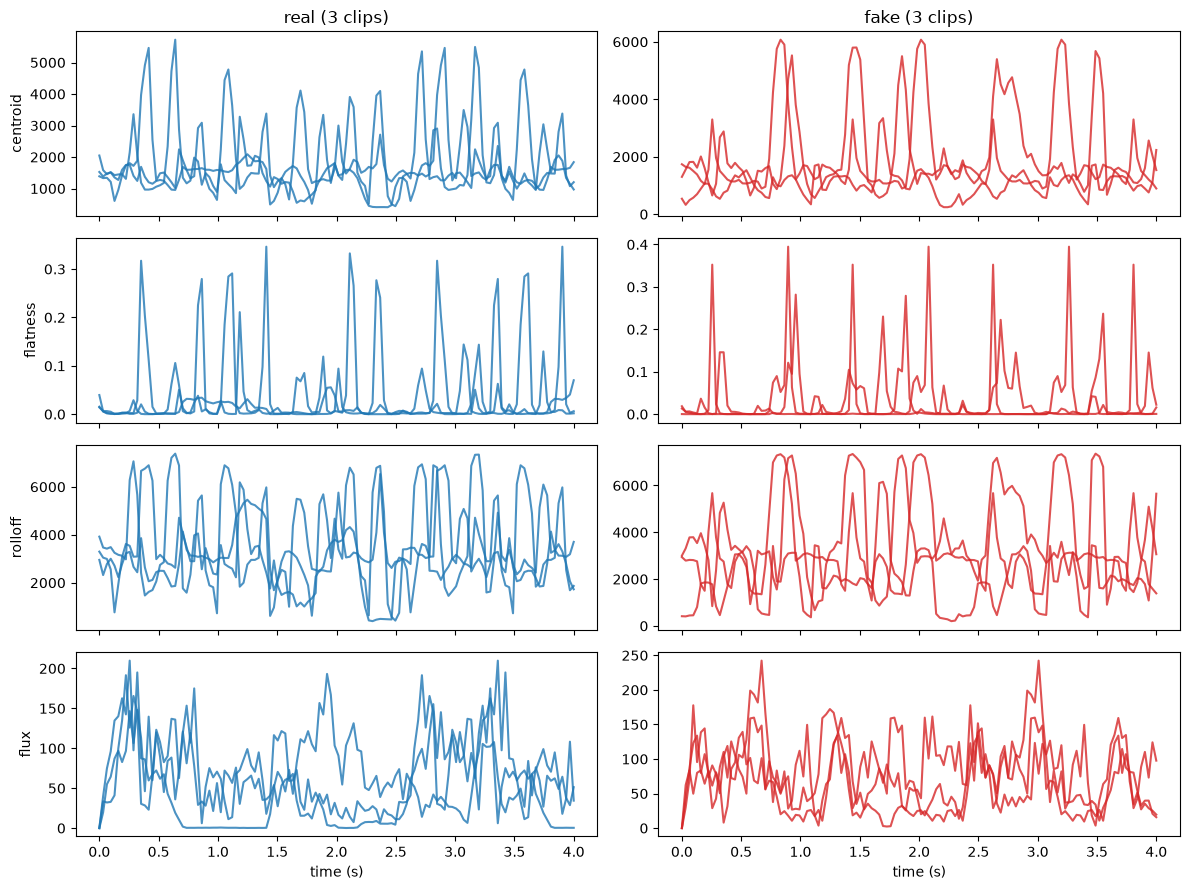

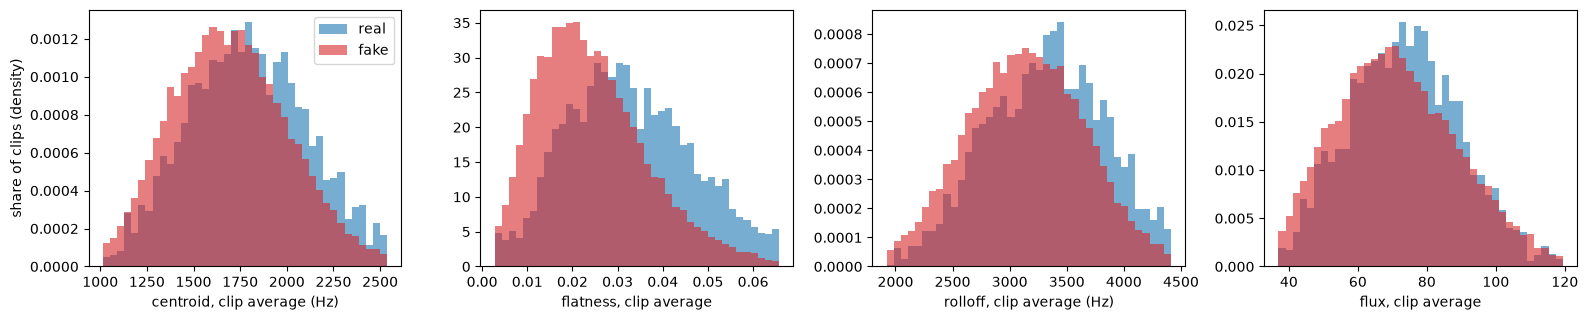

In [39]:
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for r, name in enumerate(ROW_NAMES["spectral"]):
    for i, label in enumerate(sample_label):
        axes[r, label].plot(t, examples["spectral"][i, r], color=COLORS[label], alpha=0.8)
    axes[r, 0].set_ylabel(name)
axes[0, REAL].set_title("real (3 clips)")
axes[0, FAKE].set_title("fake (3 clips)")
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
plt.tight_layout()

# Per clip: average of each row over time
show_distributions("spectral")

**What stands out**

- All four lines jump around from frame to frame, in step with the speech. The centroid and rolloff swing up during hissy sounds (the centroid reaches 4,000 to 6,000 Hz, the rolloff about 7,000 Hz) and drop back during vowels (centroid around 1,000 to 2,000 Hz).
- Flatness is close to zero almost everywhere (tonal sound) with sharp spikes up to 0.3 or 0.4 at the same moments the centroid spikes. Those are the noise-like sounds.
- Flux starts at 0 by definition. In the real examples it sits close to 0 for stretches, which are the pauses. In the fake examples it rarely drops to 0. Again, three clips each.
- Across all train clips, the per-clip averages of centroid, rolloff and flux overlap closely. Flatness is the one with a visible shift: fake clips peak around 0.02, real clips around 0.03, and real clips have a longer tail out to about 0.06.

### Pitch

Two rows per frame: the pitch in Hz (missing where no pitch is found, so gaps in the dots are unvoiced sounds and pauses) and the probability that the frame is voiced (gray line).

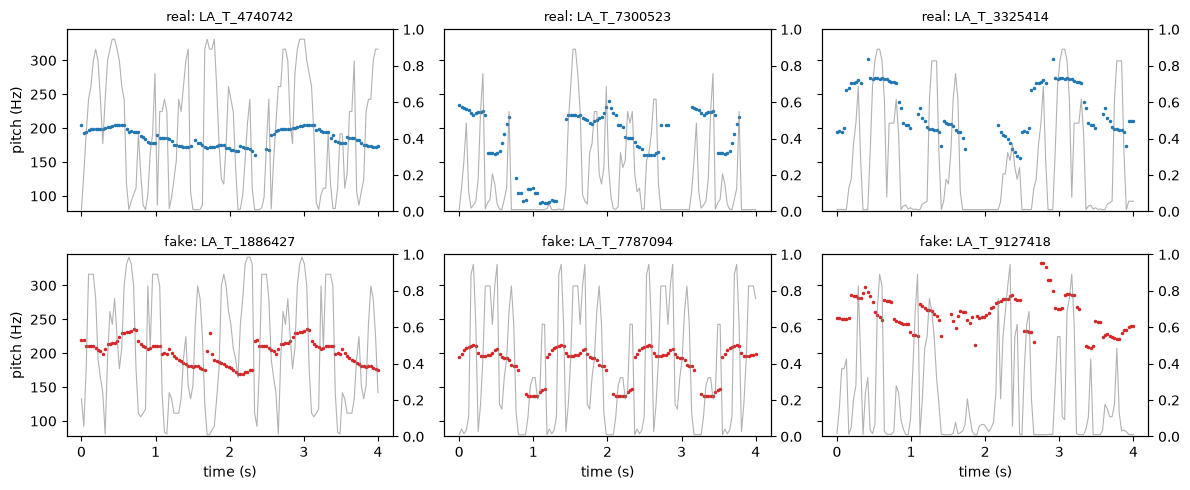

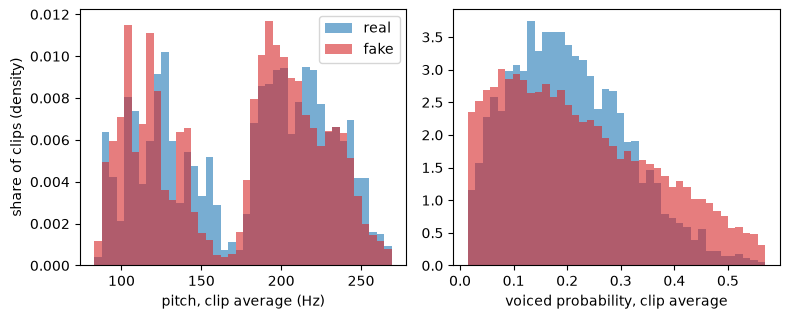

In [40]:
fig, axes = plt.subplots(2, n_each, figsize=(4 * n_each, 5), sharex=True, sharey=True)
for i, ax in enumerate(axes.ravel()):
    f0, voiced = examples["pitch"][i]
    ax.plot(t, f0, ".", ms=3, color=COLORS[sample_label[i]])
    twin = ax.twinx()  # gray line: how sure the tracker is that the frame is voiced
    twin.plot(t, voiced, color="gray", lw=0.8, alpha=0.6)
    twin.set_ylim(0, 1)
    ax.set_title(clip_title(i), fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("pitch (Hz)")
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
plt.tight_layout()

# Per clip: average pitch over the voiced frames, and the average voiced probability
show_distributions("pitch")

**What stands out**

- The pitch track is broken into runs of dots, with gaps wherever the sound is not voiced. The gray voiced probability rises to near 1 during vowels and falls to near 0 in pauses and hissy sounds.
- The speakers differ a lot. The examples sit at about 100 to 230 Hz (second real clip), about 170 to 205 Hz (first real clip), and about 210 to 330 Hz (third fake clip). Within a clip the pitch glides slowly down or up.
- A few isolated dots sit away from their neighbors (for example near 1 s in the second real clip), which may be tracking errors.
- Across all train clips, the average pitch per clip forms two humps for both real and fake, one at about 100 to 150 Hz and one at about 180 to 250 Hz. That probably reflects lower and higher voices, though the data does not say.
- The average voiced probability is low for most clips (the bulk is between 0.05 and 0.4), since a lot of every clip is unvoiced. The fake histogram has more clips at the high end (0.3 to 0.55) than the real one.

### Jitter and shimmer

How much the pitch period (jitter) and the loudness of each pitch pulse (shimmer) vary from one voice pulse to the next, as one pair of numbers for the whole clip. Small values mean a very steady voice. The table shows the six example clips, and the histograms show all train clips.

,jitter,shimmer
real: LA_T_4740742,0.0192,0.0715
real: LA_T_7300523,0.0168,0.0760
real: LA_T_3325414,0.0275,0.0852
fake: LA_T_1886427,0.0150,0.0895
fake: LA_T_7787094,0.0094,0.0855
fake: LA_T_9127418,0.0241,0.0933


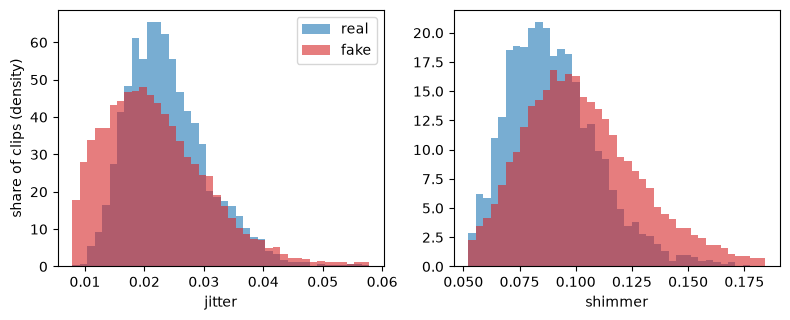

In [41]:
table = pd.DataFrame(
    examples["jitter_shimmer"], columns=ROW_NAMES["jitter_shimmer"], index=[clip_title(i) for i in range(len(sample_idx))]
)
display(table.round(4))
show_distributions("jitter_shimmer")

**What stands out**

- Both are small fractions: jitter is mostly 1% to 5% and shimmer 5% to 18%. The histograms are drawn between the 1st and 99th percentile of the clips, so a few extreme clips are cut off.
- Both have a long right tail: most clips are at the low end, with a minority much higher than the rest.
- Jitter: the fake clips are shifted to lower values, with a peak around 0.015 to 0.02 against about 0.022 for real, and a lower tail down to about 0.008.
- Shimmer goes the other way: the real clips are tighter, around 0.08 to 0.09, and the fake clips are broader with a longer right tail, up to about 0.18.
- Both numbers come from the whole clip, so one value per clip is all there is, and a clip with very little voiced sound would give an unreliable value.

### Noise

The mean and spread (in dB) of the level of the quietest 20% of frames, a rough clue to the recording noise. One pair of numbers per clip. Because the silence at the start and end was trimmed, the quietest frames are the pauses inside the clip.

,noise_mean_db,noise_std_db
real: LA_T_4740742,-28.200001,3.20
real: LA_T_7300523,-60.639999,1.31
real: LA_T_3325414,-42.930000,11.53
fake: LA_T_1886427,-29.889999,6.53
fake: LA_T_7787094,-30.110001,1.84
fake: LA_T_9127418,-26.580000,2.33


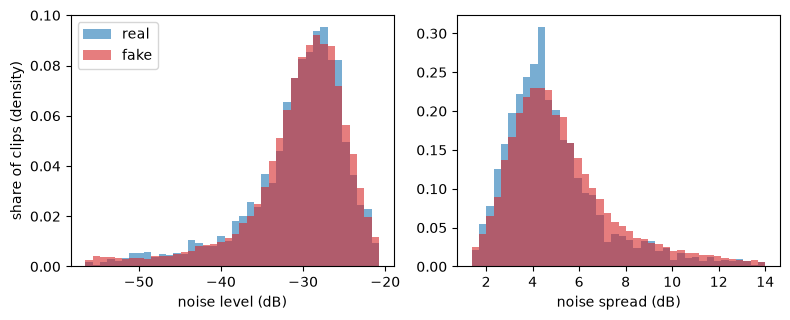

In [42]:
table = pd.DataFrame(
    examples["noise"], columns=ROW_NAMES["noise"], index=[clip_title(i) for i in range(len(sample_idx))]
)
display(table.round(2))
show_distributions("noise")

**What stands out**

- The noise level of the six example clips is spread over a wide range, from -26.6 dB to -60.6 dB. The two lowest are real clips: the second real clip (-60.6 dB) and the third (-42.9 dB). These are the same two real clips with the long, deep pauses in the log-mel plot above. That fits how the feature is built: the quietest 20% of frames are the pauses, so a clip with deep pauses gets a very low value.
- The spread (std) ranges from 1.3 dB to 11.5 dB in the examples. The 11.5 dB case is the same third real clip, where the quiet frames range from very quiet to moderately quiet.
- Across all train clips the average noise level peaks at about -27 dB for both real and fake, with a long tail of clips down to -55 dB. The two histograms are almost identical.
- The spread peaks at about 4 dB for both, with a tail out to 14 dB. Real is slightly more concentrated at the peak.

## How Well Does Each Number Separate Real from Fake?

Each number is used **on its own** to separate real from fake, the same score as the silence check in the first notebook. It is 0.5 if the number tells us nothing and 1.0 if it separates the labels perfectly.

Two things to look for:

- **Close to 0.5:** the number carries no information about real versus fake.
- **Above about 0.9:** suspiciously good. A single number rarely separates this well, so it may be a shortcut in the data rather than a property of the voice.

In [43]:
def auc_per_column(table, y):
    """Raw score per column: above 0.5 means higher values are more likely fake."""
    out = {}
    for col in table.columns:
        v = table[col].to_numpy()
        ok = np.isfinite(v)
        out[col] = roc_auc_score(y[ok], v[ok]) if ok.any() and len(np.unique(y[ok])) == 2 else np.nan
    return pd.Series(out)


auc = pd.DataFrame({s: auc_per_column(summary[s], labels[s]["label"].to_numpy()) for s in summary})
auc["group"] = group
auc["separation"] = 0.5 + (auc["train"] - 0.5).abs()  # train score, direction ignored

In [44]:
by_group = auc.groupby("group")["separation"].agg(best="max", median="median", count="size").round(3)
by_group = by_group.loc[list(FEATURES)]
by_group

,best,median,count
group,,,
mfcc,0.691,0.537,120
lfcc,0.710,0.575,40
logmel,0.745,0.587,160
cqt,0.662,0.528,168
spectral,0.685,0.596,8
pitch,0.615,0.538,5
jitter_shimmer,0.649,0.616,2
noise,0.551,0.531,2


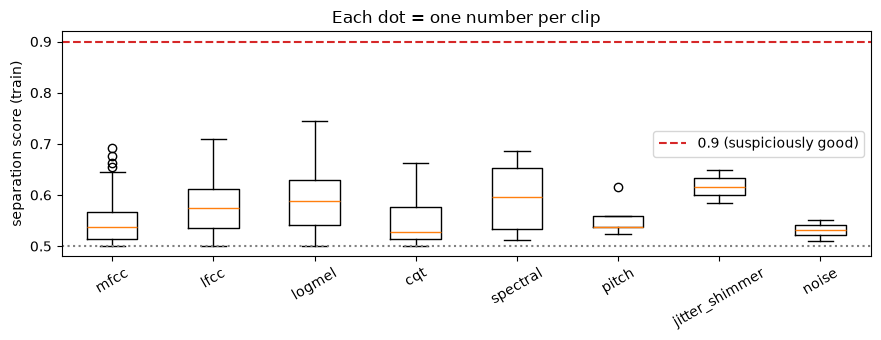

In [45]:
fig, ax = plt.subplots(figsize=(9, 3.5))
data = [auc[auc.group == f]["separation"].dropna() for f in FEATURES]
ax.boxplot(data, tick_labels=list(FEATURES))
ax.axhline(0.5, color="gray", linestyle=":")
ax.axhline(0.9, color="tab:red", linestyle="--", label="0.9 (suspiciously good)")
ax.set_ylabel("separation score (train)")
ax.set_title("Each dot = one number per clip")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()

In [46]:
# The 15 numbers that separate real from fake best
auc.sort_values("separation", ascending=False).head(15)[["train", "dev", "separation"]].round(3)

,train,dev,separation
logmel:logmel79:mean,0.255,0.269,0.745
lfcc:lfcc18:mean,0.290,0.294,0.710
lfcc:lfcc0:mean,0.300,0.304,0.700
logmel:logmel29:mean,0.308,0.368,0.692
mfcc:mfcc0:mean,0.309,0.313,0.691
lfcc:lfcc5:mean,0.689,0.709,0.689
spectral:flatness:mean,0.315,0.353,0.685
logmel:logmel30:mean,0.317,0.359,0.683
logmel:logmel28:mean,0.323,0.344,0.677
mfcc:mfcc3:std,0.676,0.670,0.676


## Do the Scores Hold on Dev?

If a number separates real from fake on train but not on dev, it learned something specific to the train clips. Each dot below is one number, plotted by its raw score on train and on dev. Dots near the diagonal behave the same on both. A dot on the opposite side of 0.5 flips direction, so higher values are fake on one set and real on the other.

correlation between train and dev scores: 0.934
numbers that flip direction on dev (train score more than 0.05 from 0.5): 1


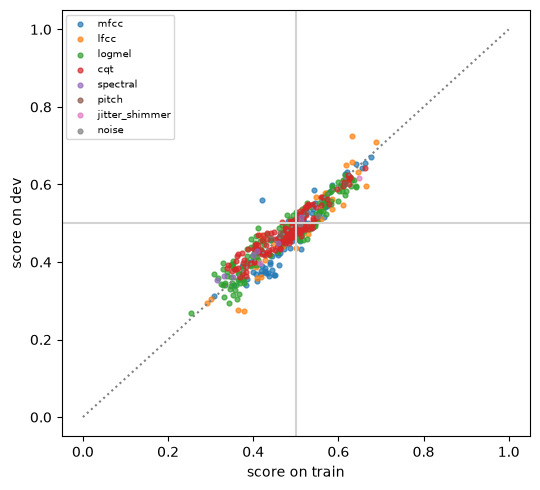

In [47]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for f in FEATURES:
    sub = auc[auc.group == f]
    ax.scatter(sub["train"], sub["dev"], s=12, alpha=0.7, label=f)
ax.plot([0, 1], [0, 1], color="gray", linestyle=":")
ax.axhline(0.5, color="lightgray")
ax.axvline(0.5, color="lightgray")
ax.set_xlabel("score on train")
ax.set_ylabel("score on dev")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()

ok = auc[["train", "dev"]].dropna()
flipped = ok[((ok["train"] - 0.5) * (ok["dev"] - 0.5) < 0) & ((ok["train"] - 0.5).abs() > 0.05)]
print(f"correlation between train and dev scores: {ok['train'].corr(ok['dev']):.3f}")
print(f"numbers that flip direction on dev (train score more than 0.05 from 0.5): {len(flipped)}")

## Features to Watch

The noise features are the ones most likely to be a dataset shortcut, because they describe the recording, not the voice. The voiced fraction and spectral flux are also shown, since they relate to how steady the sound is.

In [48]:
watch = ["noise:noise_mean_db", "noise:noise_std_db", "pitch:voiced_fraction",
         "spectral:flux:mean", "spectral:flux:std"]
auc.loc[watch, ["train", "dev", "separation"]].round(3)

,train,dev,separation
noise:noise_mean_db,0.511,0.498,0.511
noise:noise_std_db,0.551,0.519,0.551
pitch:voiced_fraction,0.615,0.602,0.615
spectral:flux:mean,0.459,0.449,0.541
spectral:flux:std,0.353,0.361,0.647


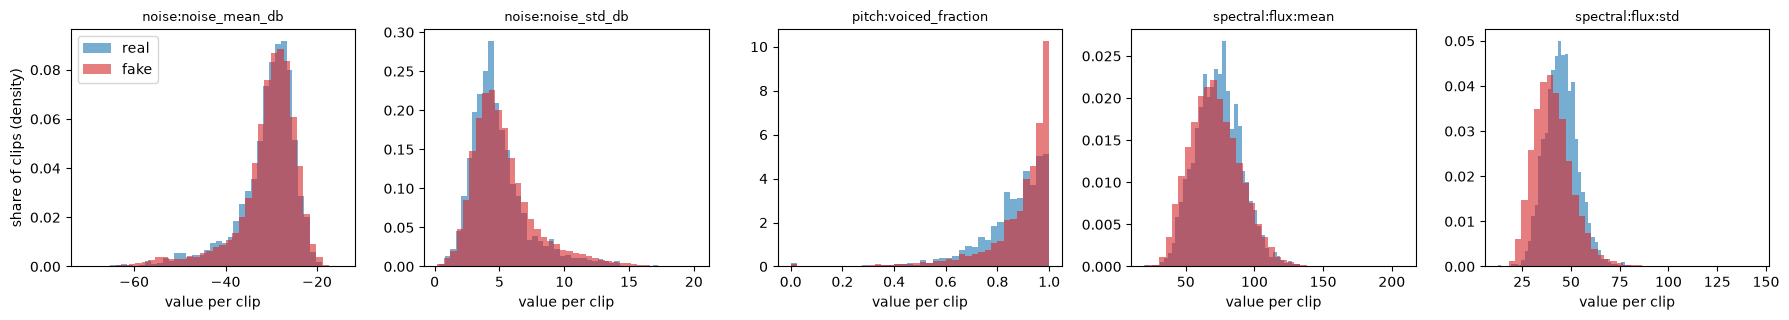

In [49]:
fig, axes = plt.subplots(1, len(watch), figsize=(18, 3.3))
for ax, col in zip(axes, watch):
    for label in (REAL, FAKE):
        vals = summary["train"][col][labels["train"]["label"] == label].dropna()
        ax.hist(vals, bins=40, alpha=0.6, density=True, color=COLORS[label], label=NAMES[label])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("value per clip")
axes[0].set_ylabel("share of clips (density)")
axes[0].legend()
plt.tight_layout()

In [50]:
suspicious = auc[auc["separation"] > 0.9]
print(f"{len(suspicious)} of {len(auc)} numbers score above 0.9 on train")
suspicious.groupby("group").size()

0 of 505 numbers score above 0.9 on train


Series([], dtype: int64)

## Summary

A score of 0.5 means a number tells us nothing, and 1.0 means it separates real from fake perfectly. Each number was tested on its own. The scores below are for train, with dev in brackets where it matters.

| Question | Finding | What we do about it |
|---|---|---|
| Is any single number too good to be true? | No. None of the 505 numbers scores above 0.9. The best is 0.745 (the highest-frequency mel band, average). | Nothing. A model combines many numbers, so moderate scores on their own are expected. |
| Do the noise features leak the label? | No. Noise mean scores 0.511 and noise spread 0.551, close to no information. | Keep them for now. They add little on their own. |
| Do the scores hold on dev? | Yes. The train and dev scores have a correlation of 0.934, and only 1 of 505 numbers flips direction. | The features should carry over to dev. |
| Which groups separate best? | The mel spectrogram (best 0.745), LFCC (0.710), MFCC (0.691), spectral (0.685) and jitter/shimmer (0.649). The top numbers mostly describe overall energy and the highest frequencies. | Keep these. |
| Does the "more regular" look from the first notebook show up? | Partly. The spread of spectral flux scores 0.647, and fakes have the lower spread, so their frame-to-frame change is steadier. The average flux scores only 0.541. | Keep the spectral features. |
| Is pitch useful? | Weakly. The voiced fraction scores 0.615, and fakes have more frames with a pitch. | Keep it for train and dev. Decide on 2021 after the phone-effects check. |
| Which groups look weakest? | CQT (best 0.662, median 0.528) and the noise features (best 0.551). | Candidates to drop, but see below. |

**Not covered yet:** each number was tested alone, so a group that looks weak here could still help in combination. Dropping features should wait for a model. These scores also come from clean audio, so the phone-effects check on dev is still to do.